# **ПОСТРОЕНИЕ КРИВОЙ ОБУЧЕНИЯ ДЛЯ КЛАССИФИКАТОРА**

В данной работе исследуется построение кривой обучения для различных алгоритмов классификации на различных датасетах.

  

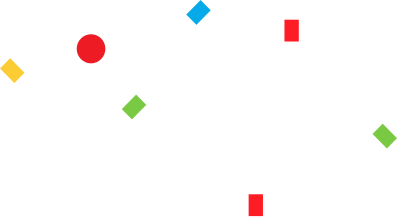


Кривая обучения (Learning curve) показывает оценку проверки и обучения модели для различного количества обучающих выборок. Это инструмент, позволяющий выяснить, какую выгоду мы получим от добавления дополнительных обучающих данных и страдает ли модель больше от ошибки дисперсии или ошибки смещения.



---



Импорт библиотек:

In [ ]:
import sys
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import balanced_accuracy_score
from sklearn.datasets import make_classification, make_circles

импорт моделей:

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA

Далее я хочу посмотреть на поведение моделей в целом для разновидных данных, поэтому план работы следующий:

1. Проверка лучшей модели для определенного датасета (check_vanila_models)
2. Построение кривой обучения (check_vanila_models)



Давайте создадим несколько датасетов с разной структурой данной, а именно:

In [ ]:
class SyntheticDataset:

    def __init__(self, n_samples=1000, random_state=42):
        self.n_samples = n_samples
        self.random_state = random_state

    def get_linear(self):

        # линейные (облака)
        X, y = make_classification(
            n_samples=self.n_samples,
            n_features=20,
            n_informative=10,
            n_redundant=0,
            n_classes=2,
            n_clusters_per_class=1,
            class_sep=3.0,
            random_state=self.random_state
        )
        return X, y

    def get_standard_binary(self):

        #1. бинарная классификация
        X, y = make_classification(
            n_samples=self.n_samples,
            n_features=20,
            n_informative=15,    # полезные признаки
            n_redundant=5,       # шум
            n_classes=2,
            random_state=self.random_state
        )
        return X, y

    def get_imbalanced(self, weights=[0.9, 0.1]):

        # несбалансированные классы
        X, y = make_classification(
            n_samples=self.n_samples,
            n_features=20,
            n_informative=10,
            n_classes=2,
            weights=weights,     # 90% данных - класс 0, 10% - класс 1
            random_state=self.random_state
        )
        return X, y

    def get_multiclass(self, n_classes=4):

        # многоклассовая классификация
        X, y = make_classification(
            n_samples=self.n_samples,
            n_features=20,
            n_informative=17,
            n_redundant=2,
            n_classes=n_classes, # 4
            random_state=self.random_state
        )
        return X, y

    def get_nonlinear(self):
        # нелинейные (вложенные кольца)
        X, y = make_circles(
            n_samples=self.n_samples,
            noise=0.15,          # шум
            factor=0.3,          # Расстояние между кольцами
            random_state=self.random_state
        )
        return X, y

Посмотрим, собственно, на структу в двухмерном пространства, используя метод PCA:

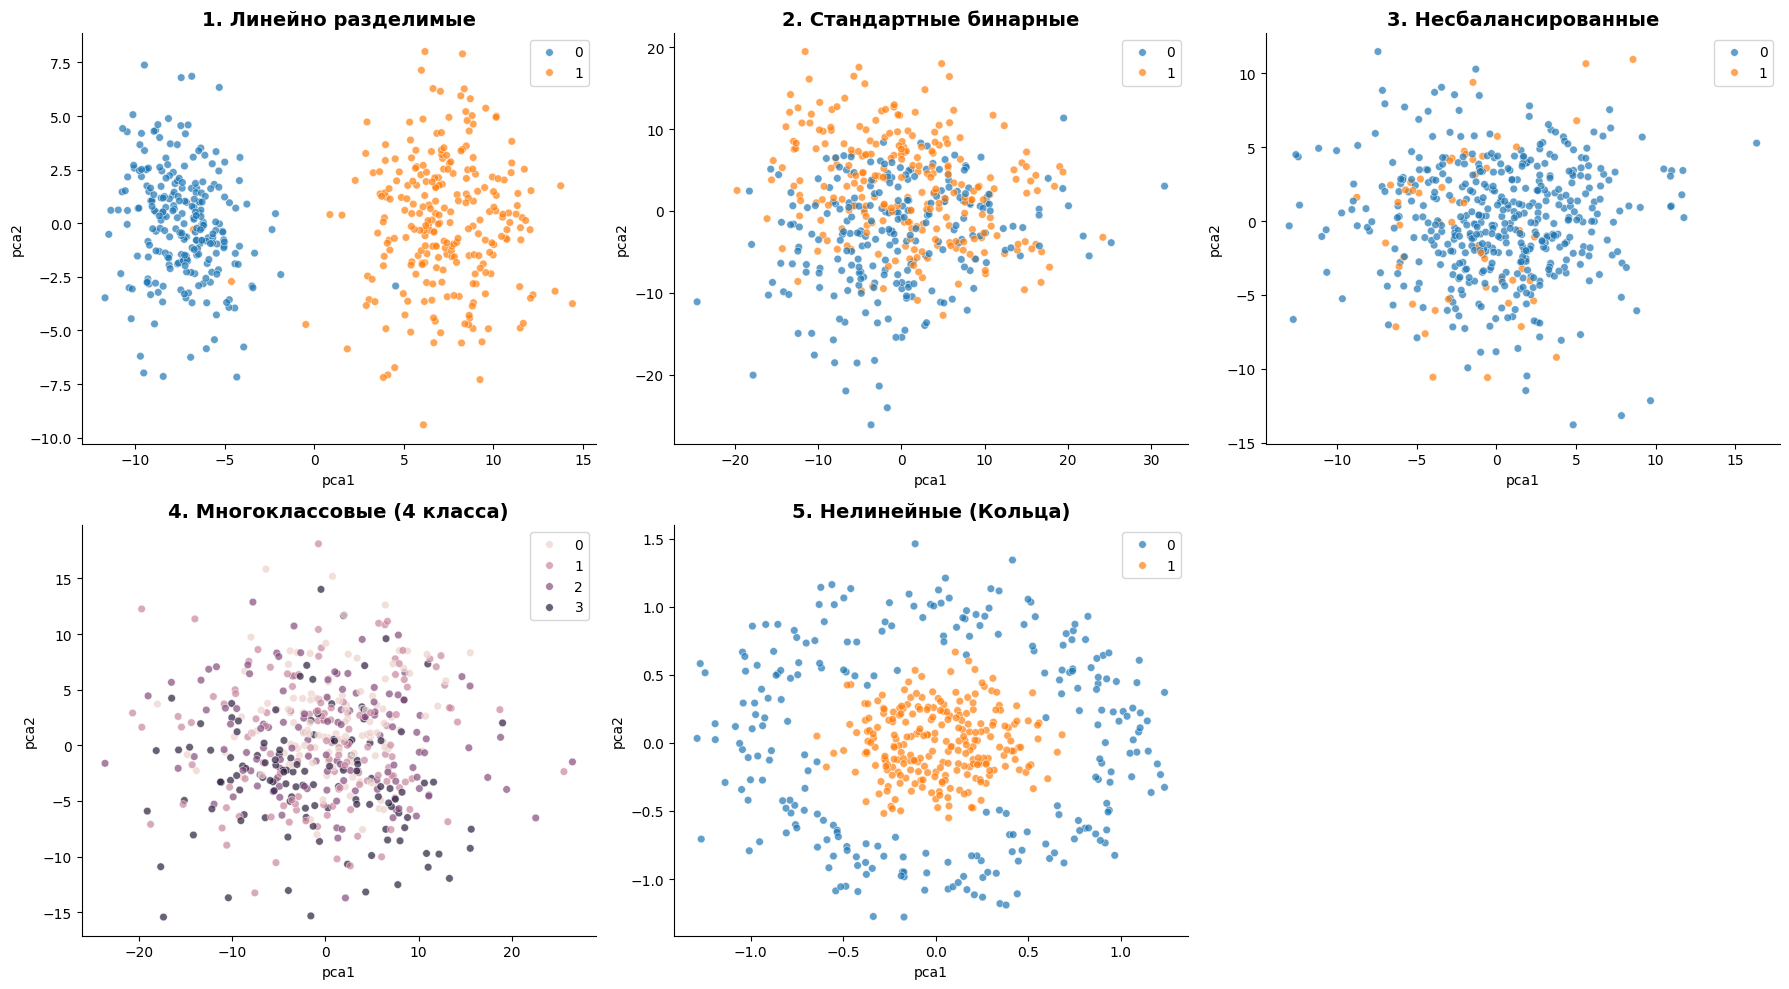

In [ ]:
data_visual = SyntheticDataset(500)
datasets = {
    "1. Линейно разделимые": data_visual.get_linear(),
    "2. Стандартные бинарные": data_visual.get_standard_binary(),
    "3. Несбалансированные": data_visual.get_imbalanced(),
    "4. Многоклассовые (4 класса)": data_visual.get_multiclass(),
    "5. Нелинейные (Кольца)": data_visual.get_nonlinear()
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

pca = PCA(n_components=2)

for i, (name, (X, y)) in enumerate(datasets.items()):
    ax = axes[i]

    if X.shape[1] > 2:
        X_plot = pca.fit_transform(X)
    else:
        X_plot = X

    # Рисуем точки
    sns.scatterplot(
        x=X_plot[:, 0],
        y=X_plot[:, 1],
        hue=y,
        ax=ax,
        alpha=0.7,
        s=30
    )

    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_xlabel("pca1")
    ax.set_ylabel("pca2")

    sns.despine(ax=ax)

fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Теперь напишем функцию для построения кривых:

In [ ]:
def check_vanila_models(X, y, start, stop, steps, n_seeds: int=1, randomize: bool=False):

  data = np.linspace(start, stop, steps)
  scaler = MinMaxScaler() # нормализация данных

  models_pool = [
        LogisticRegression(),
        RandomForestClassifier(),
        AdaBoostClassifier(),
        GaussianProcessClassifier(),
        GaussianNB(),
        KNeighborsClassifier(),
        SVC(),
        DecisionTreeClassifier()
    ]

  # словарь для моделей
  models_results = {type(model).__name__: {'train': [], 'test': []} for model in models_pool}

  # рзбивка выборок
  for split in data:

    step_scores_test = {type(model).__name__: 0 for model in models_pool} # словарь оценок
    step_scores_train = {type(model).__name__: 0 for model in models_pool} # словарь оценок

    # Монте-Карло кросс-валидация
    for k in range(1, n_seeds + 1):

      X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=split, random_state=k, stratify=y)

      X_train_scaled = scaler.fit_transform(X_train)
      X_test_scaled = scaler.transform(X_test)

      # оценка точности
      for model in models_pool:

        model_name = type(model).__name__
        model.fit(X_train_scaled, y_train)

        y_pred_train = model.predict(X_train_scaled)
        step_scores_train[model_name] += balanced_accuracy_score(y_train, y_pred_train)

        y_pred_test = model.predict(X_test_scaled)
        step_scores_test[model_name] += balanced_accuracy_score(y_test, y_pred_test)

    for model_name in models_results:
        models_results[model_name]['train'].append(step_scores_train[model_name] / n_seeds)
        models_results[model_name]['test'].append(step_scores_test[model_name] / n_seeds)


  fig, axes = plt.subplots(2, 4, figsize=(20, 10))
  axes = axes.flatten()
  train_sizes = 1 - data # долю теста в долю трейна

  for i, (model_name, scores) in enumerate(models_results.items()):

    ax = axes[i]
    sns.lineplot(x=train_sizes, y=scores['train'], marker='o', label='Train', ax=ax)
    sns.lineplot(x=train_sizes, y=scores['test'], marker='o', label='Test', ax=ax)

    ax.set_title(model_name, fontsize=14)
    ax.set_xlabel('train set size')
    ax.set_ylabel('Accuracy')
    ax.set_ylim(0.3, 1.05)
    ax.grid()
    ax.legend()

  plt.show()


# Прогон датасетов

1. Линейная модель:

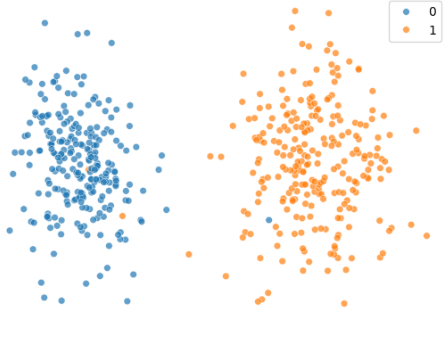

Лидирующая модель: в целом все хорощо справились кроме AdaBoostClassifer and Decision TreeClassifier

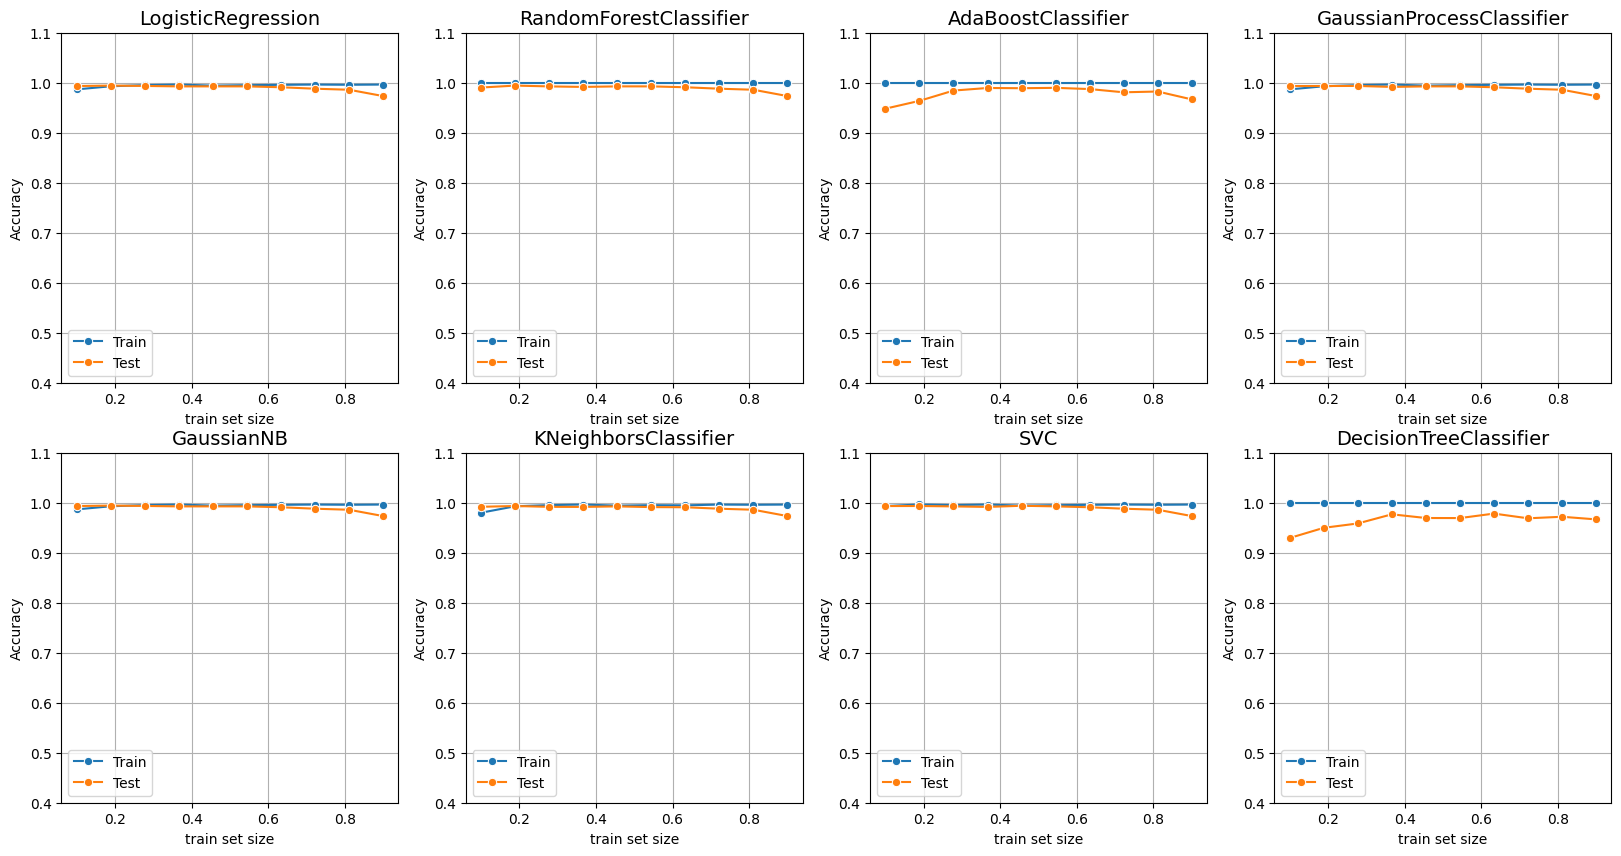

In [ ]:
sample = SyntheticDataset(500)
X, y = sample.get_linear()
check_vanila_models(X, y, start=0.9, stop=0.1, steps=10, n_seeds=3)

2. Стандартный бинарный

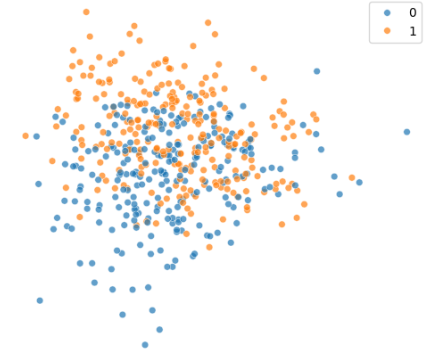

SVC is win. По тестовым данным еще хорощо справились RandomForest and DecisionTree, но точность тестовой выборки хуже, чем на обучающейся + у трейна везде 1, что может свидельствовать о переобучении модели. Для них в данном датасете нужно настраивать гиперпараметры (у деревьев это глубина самого дерева)

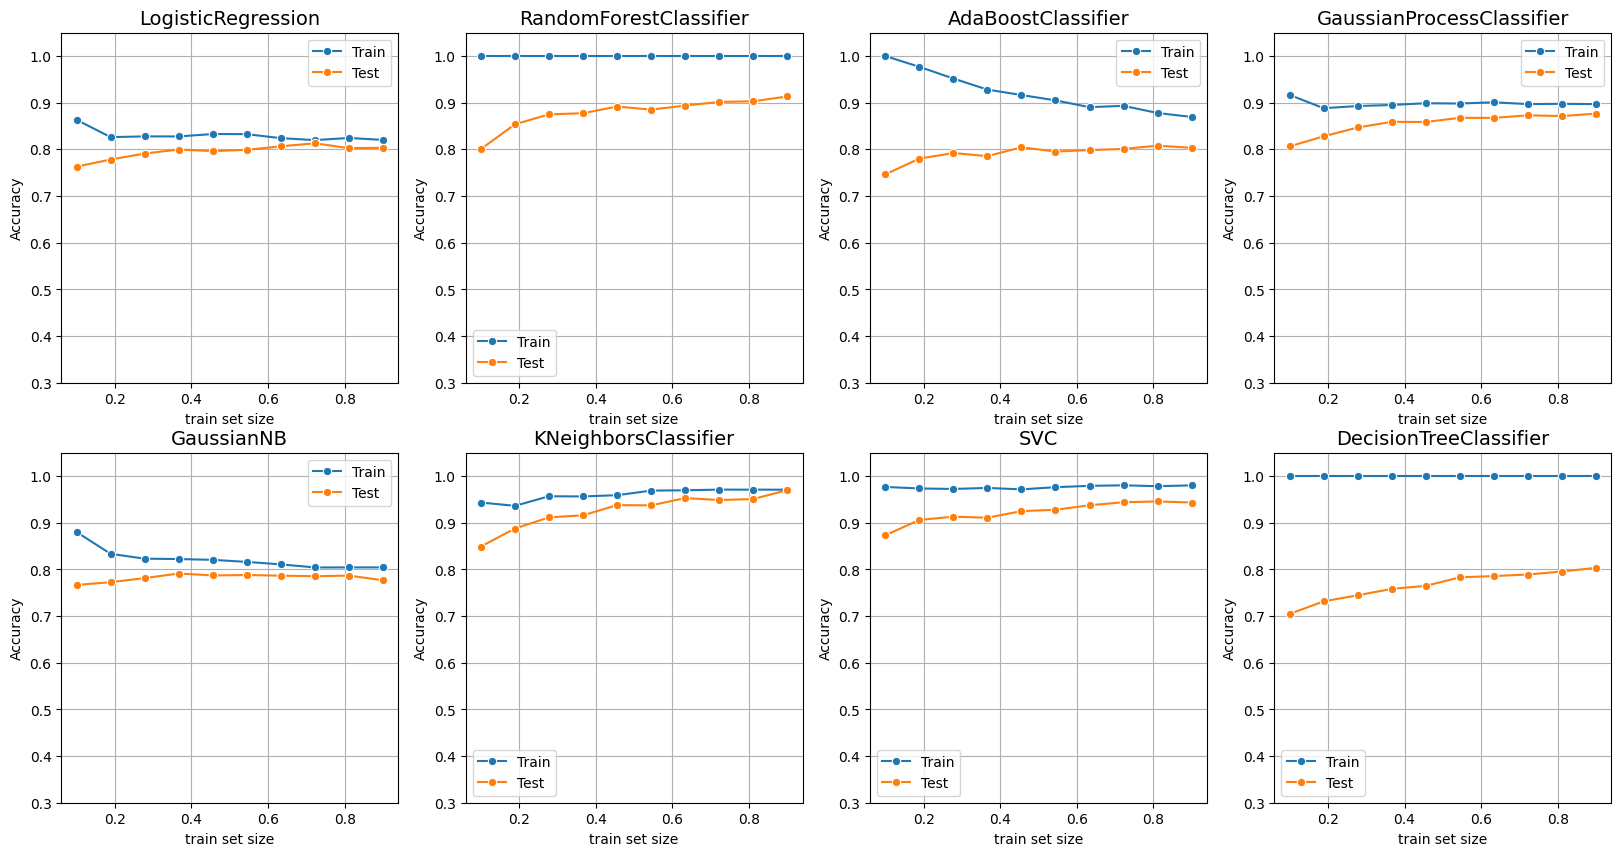

In [ ]:
sample = SyntheticDataset(1000)
X, y = sample.get_standard_binary()
check_vanila_models(X, y, start=0.9, stop=0.1, steps=10, n_seeds=3)

3. Несбалансированная бинарная выборка

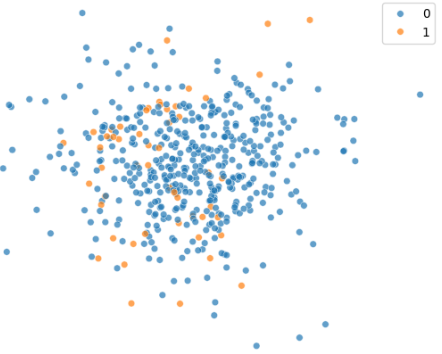

Победитель - AdaBoostClassifier. Еще можно выделить Наивный Баессовский, он неплохо уловил структуру, но все равно отстал от бустинга. RandomForest и DecisionTree снова показывают идеальную прямую 1.0 на тренировочной выборке, что говорит опять о переобучение.

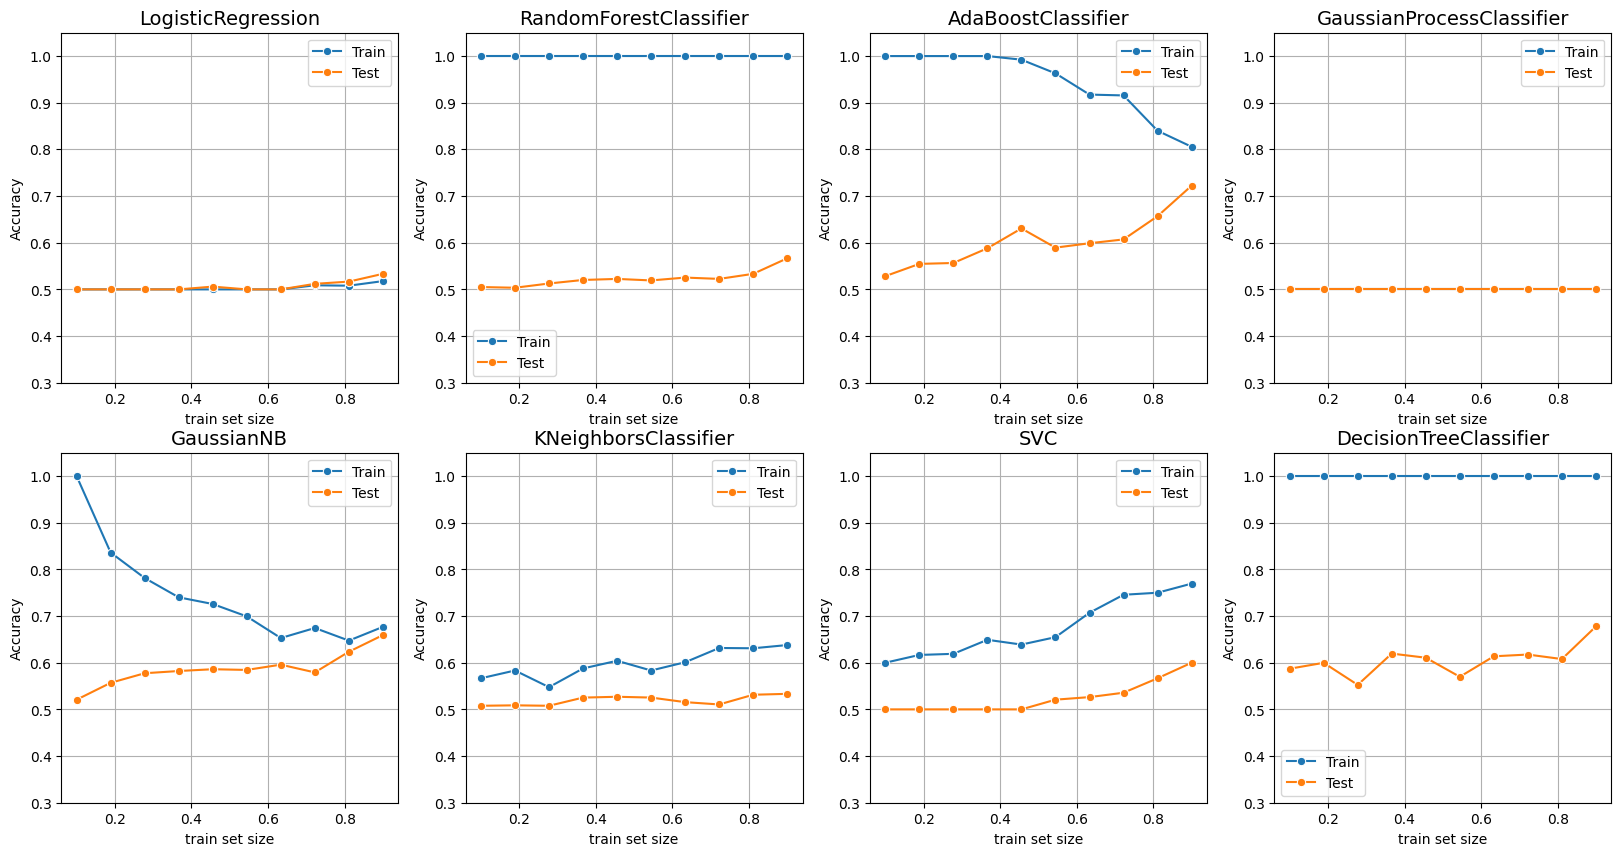

In [ ]:
X, y = sample.get_imbalanced()
check_vanila_models(X, y, start=0.9, stop=0.1, steps=10, n_seeds=3)

4. Несколько классовый

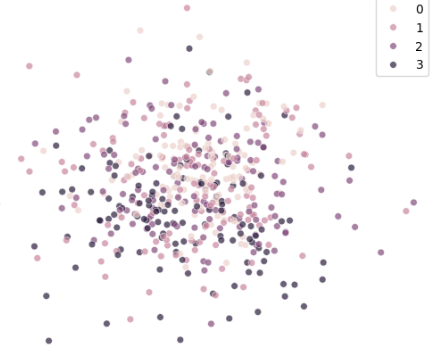

KNeighbors справился относительно лучше остальных.

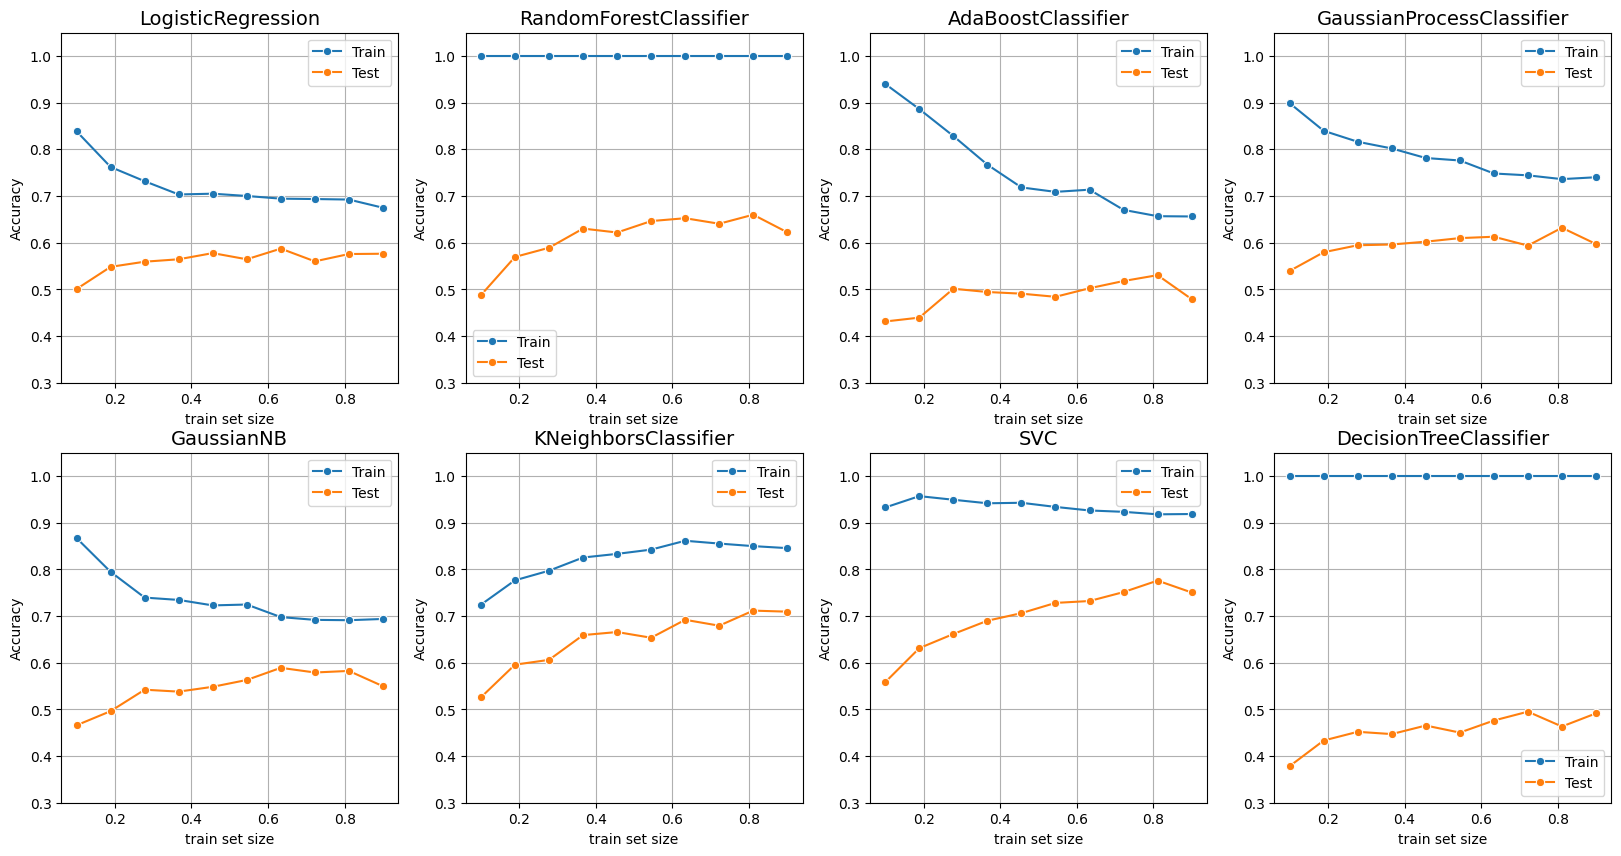

In [ ]:
X, y = sample.get_multiclass()
check_vanila_models(X, y, start=0.9, stop=0.1, steps=10, n_seeds=3)

5. Данные в виде колец

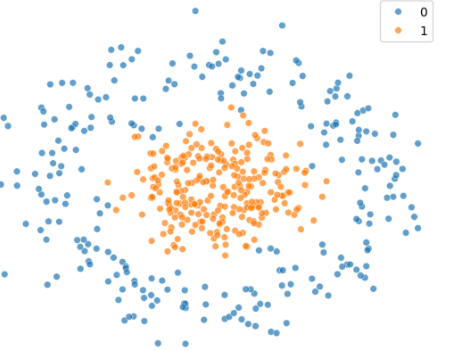

А тут уже наоборот - деревья показали улучшенные результаты для сложной структуры данных. Такжи хорошо показали себя SVC и KNeighbors

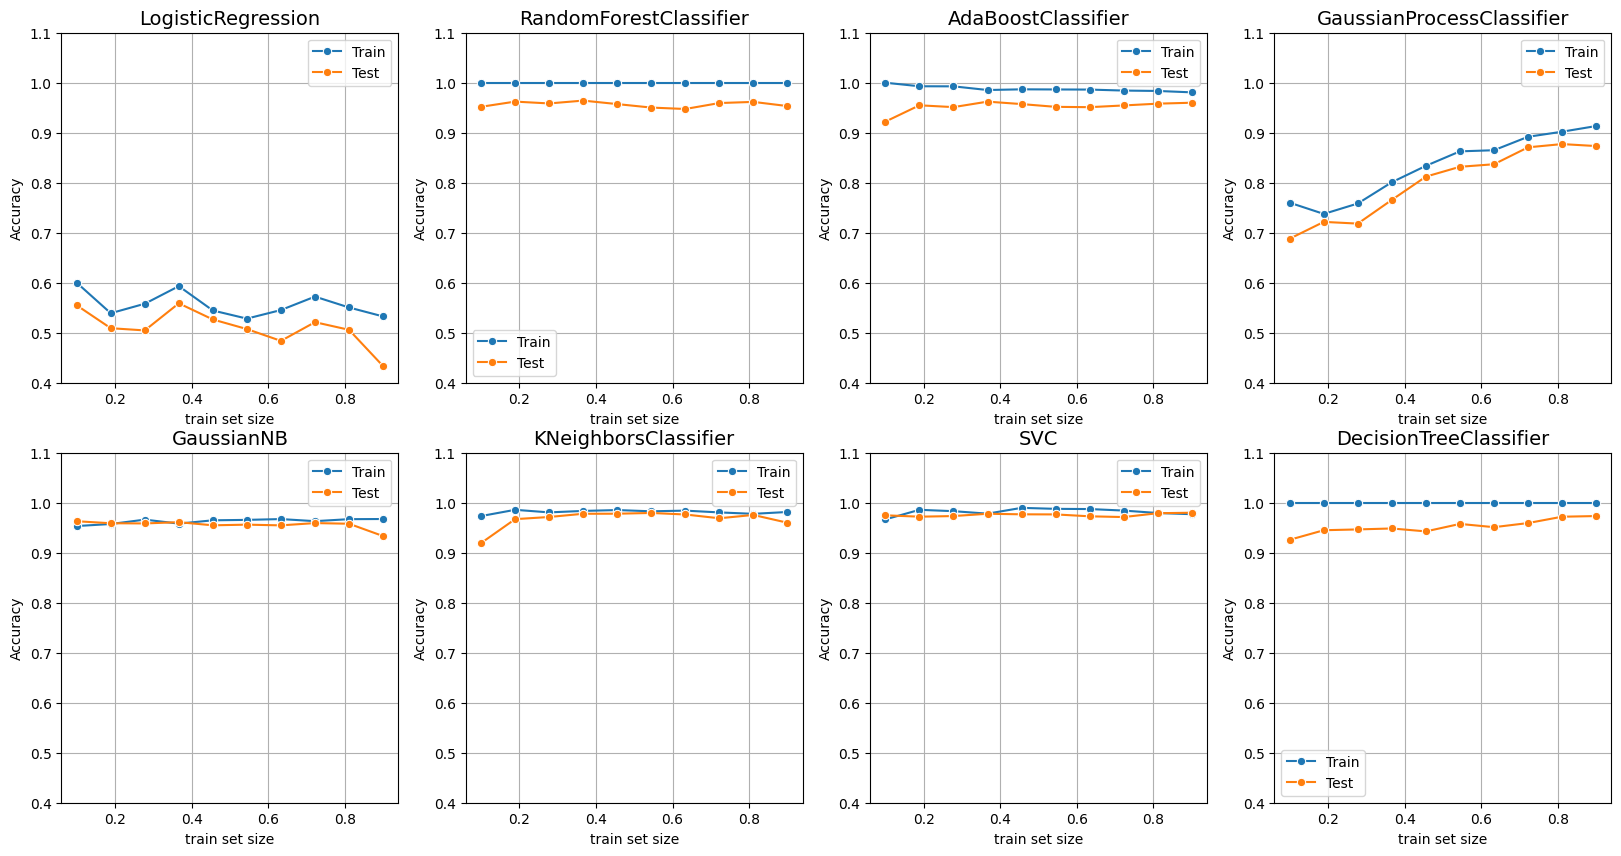

In [ ]:
X, y = sample.get_nonlinear()
check_vanila_models(X, y, start=0.9, stop=0.1, steps=10, n_seeds=3)

Источники:
1. https://scikit-learn.ru/stable/modules/learning_curve.html